# FIGNN Validation

This notebook evaluates the existing 29-subject LOSO outputs.

## Primary question

Does the learned representation produce an emergent workload trajectory

\[
C_0 ightarrow C_1 ightarrow C_2
\]

where the 1-back representation lies between the 0-back and 2-back representations?

### Primary criterion

`oneback_between_x`

This is stronger than the supporting criterion:

\[
d(C_0,C_1) < d(C_0,C_2)
\]

The notebook also evaluates:

- subject-level exact confidence intervals and binomial tests;
- the three subjects that satisfy the weaker distance criterion but fail the stronger trajectory criterion;
- Stage-2 calibration baselines, when their output files are available;
- frozen-model PLV-threshold sensitivity, when threshold outputs are available;
- ablation results after the training/evaluation pipeline finishes.

Procrustes is retained only as a supplementary descriptive metric.


In [12]:
from pathlib import Path
import json
import os
import re
import glob
import pickle
import copy
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import binomtest
from statsmodels.stats.proportion import proportion_confint

from sklearn.linear_model import LinearRegression

import torch
from torch_geometric.loader import DataLoader

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/home/nvidia/24BCE1793/fignn_cni__project"
)

OUTPUT_ROOT = Path(
    "/lp-dev/24BCE1793/outputs"
)

DATA_ROOT = Path(
    "/lp-dev/24BCE1793/data"
)

FIG_DIR = OUTPUT_ROOT / "evaluation_loso_all29" / "validation_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# Main LOSO validation files
# ------------------------------------------------------------

BASE_DIR = OUTPUT_ROOT / "evaluation_loso_all29"

REPORT_PATH = BASE_DIR / "loso_all29_report.json"
SUBJECT_CSV = BASE_DIR / "loso_all29_subject_metrics.csv"

with open(REPORT_PATH, "r") as f:
    report = json.load(f)

df = pd.read_csv(SUBJECT_CSV)

assert len(df) == 29
assert df["subject"].nunique() == 29

n = len(df)

d01_lt_d02 = df["d01_x"] < df["d02_x"]
between_x = df["oneback_between_x"].astype(bool)
between_y = df["oneback_between_y"].astype(bool)

print(f"Loaded {n} LOSO subjects.")

Loaded 29 LOSO subjects.


## 1. Primary trajectory result

The weaker condition only checks whether 1-back is closer to 0-back than 2-back is.

The stronger condition checks whether the projected 1-back position lies within the 0-back to 2-back segment and satisfies the perpendicular-distance rule used by the evaluation pipeline.

Therefore, the stronger `oneback_between_x` criterion is the primary result.


In [2]:
def exact_ci(k, n):
    low, high = proportion_confint(k, n, alpha=0.05, method="beta")
    return 100 * low, 100 * high

primary_rows = []

for label, mask in [
    ("Weak: d01 < d02", d01_lt_d02),
    ("Primary: 1-back between, X", between_x),
    ("Secondary: 1-back between, Y", between_y),
]:
    k = int(mask.sum())
    low, high = exact_ci(k, n)

    primary_rows.append({
        "criterion": label,
        "successes": k,
        "total": n,
        "proportion_%": 100 * k / n,
        "95% CI": f"{low:.1f}%–{high:.1f}%",
        "one-sided_binomial_p_vs_0.5": binomtest(
            k, n, p=0.5, alternative="greater"
        ).pvalue,
    })

primary_results = pd.DataFrame(primary_rows)
display(primary_results.round(4))


,criterion,successes,total,proportion_%,95% CI,one-sided_binomial_p_vs_0.5
0,Weak: d01 < d02,28,29,96.5517,82.2%–99.9%,0.0000
1,"Primary: 1-back between, X",25,29,86.2069,68.3%–96.1%,0.0001
2,"Secondary: 1-back between, Y",25,29,86.2069,68.3%–96.1%,0.0001


In [3]:
# Identify the subjects that satisfy the weak condition but fail the stronger between-segment criterion.

weak_only = df.loc[
    d01_lt_d02 & ~between_x,
    [
        "subject",
        "d01_x",
        "d02_x",
        "d12_x",
        "relative_1back_position",
        "perpendicular_distance",
        "angle_deg",
        "path_efficiency",
        "oneback_between_x",
        "oneback_between_y",
    ]
].sort_values("subject")

print(
    f"{len(weak_only)} subjects satisfy d01 < d02 "
    "but fail the stronger between-segment criterion."
)

display(weak_only)


3 subjects satisfy d01 < d02 but fail the stronger between-segment criterion.


,subject,d01_x,d02_x,d12_x,relative_1back_position,perpendicular_distance,angle_deg,path_efficiency,oneback_between_x,oneback_between_y
1,2,0.027437,0.080379,0.091393,-0.088151,0.026506,121.825569,0.676426,False,False
10,11,0.024200,0.035203,0.043984,-0.044250,0.024150,126.993729,0.516292,False,False
11,12,0.008166,0.025151,0.030825,-0.198330,0.006466,139.758499,0.645048,False,False


### Interpretation of the three weak-only subjects

These subjects are not automatically errors.

They demonstrate why `d01 < d02` is insufficient by itself:

- `d01 < d02` means only that 1-back is closer to 0-back than 2-back is.
- It does not guarantee that 1-back lies on the 0-back → 2-back trajectory.
- A subject can satisfy the distance inequality while having a projection position outside `[0, 1]`, or while deviating too far from the endpoint line.

The manuscript should therefore report:

> The weak distance ordering was observed in 28/29 subjects, while the stronger between-segment trajectory criterion was observed in 25/29 subjects.


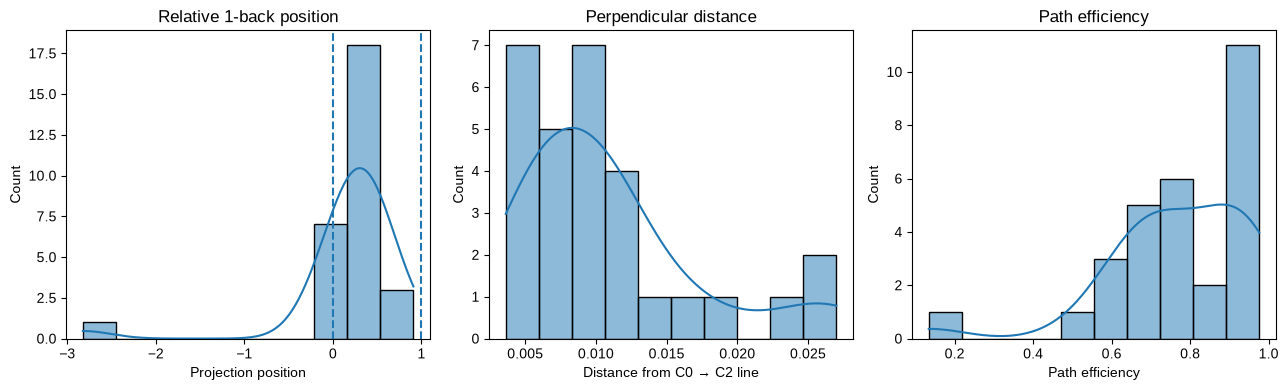

In [4]:
# Compact geometry plot: the quantities directly related to the primary criterion.

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

sns.histplot(df["relative_1back_position"], bins=10, kde=True, ax=axes[0])
axes[0].axvline(0, linestyle="--")
axes[0].axvline(1, linestyle="--")
axes[0].set_title("Relative 1-back position")
axes[0].set_xlabel("Projection position")

sns.histplot(df["perpendicular_distance"], bins=10, kde=True, ax=axes[1])
axes[1].set_title("Perpendicular distance")
axes[1].set_xlabel("Distance from C0 → C2 line")

sns.histplot(df["path_efficiency"], bins=10, kde=True, ax=axes[2])
axes[2].set_title("Path efficiency")
axes[2].set_xlabel("Path efficiency")

plt.tight_layout()
plt.savefig(FIG_DIR / "primary_geometry.png", dpi=300, bbox_inches="tight")
plt.show()


## 2. Stage-2 calibration baselines

This section expects the Stage-2 pipeline to export one row per subject and method.

Required methods:

- `population_only`
- `midpoint`
- `regression`
- `geometric_calibration`

The comparison must use the same held-out subjects and the same evaluation metrics for every method.

**Important:** this notebook cannot recreate Stage-2 calibration from the final summary CSV alone. The calibration pipeline must first export the per-subject baseline results.


In [11]:
# ============================================================
# STAGE 2 — LOSO CALIBRATION BASELINE COMPARISON
#
# Methods:
#   1. population_only
#   3. midpoint
#   4. regression
#   5. frozen_geometric
#
# Evaluation:
#   64-D Euclidean error against the unseen subject's true 1B
#   centroid.
# ============================================================
# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = "/home/nvidia/24BCE1793/fignn_cni__project"

GRAPHS_PATH = (
    "/lp-dev/24BCE1793/data/processed/"
    "all_graphs_29sub.pkl"
)

LOSO_ROOT = (
    "/lp-dev/24BCE1793/outputs/loso"
)

OUTPUT_DIR = (
    "/lp-dev/24BCE1793/outputs/stage2_calibration"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "stage2_baseline_results.csv"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

sys.path.insert(0, PROJECT_ROOT)

from src.models.model import FIGNNEncoder


# ============================================================
# LOAD ALL GRAPHS
# ============================================================

print("Loading graphs...")

with open(GRAPHS_PATH, "rb") as f:
    all_graphs = pickle.load(f)

print(f"Loaded {len(all_graphs)} graphs")


# ============================================================
# FIND LOSO CHECKPOINTS
# ============================================================

checkpoint_files = glob.glob(
    os.path.join(
        LOSO_ROOT,
        "**",
        "fignn_final.pth",
    ),
    recursive=True,
)

if not checkpoint_files:
    raise FileNotFoundError(
        f"No LOSO checkpoints found under:\n{LOSO_ROOT}"
    )

subject_checkpoints = {}

for path in checkpoint_files:
    match = re.search(
        r"subject[_-]?(\d+)",
        path,
        re.IGNORECASE,
    )

    if match:
        subject = int(match.group(1))
        subject_checkpoints[subject] = path

print(
    f"Found {len(subject_checkpoints)} LOSO checkpoints"
)

if len(subject_checkpoints) == 0:
    raise RuntimeError(
        "No subject-specific LOSO checkpoints were detected."
    )


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# NORMALIZATION
# ============================================================

def compute_train_stats(graphs):
    """
    Compute normalization statistics using only the 28
    LOSO training subjects.
    """

    all_x = torch.cat(
        [g.x for g in graphs],
        dim=0,
    )

    mean = all_x.mean(dim=0)

    std = (
        all_x.std(dim=0)
        .clamp(min=1e-8)
    )

    return mean, std


# ============================================================
# FROZEN ENCODER EMBEDDINGS
# ============================================================

@torch.no_grad()
def get_embeddings(
    model,
    graphs,
    mean,
    std,
    device,
    batch_size=128,
):
    """
    Generate frozen 64-D embeddings.
    """

    processed_graphs = []

    for graph in graphs:
        graph_copy = copy.copy(graph)

        graph_copy.x = (
            graph.x.clone() - mean
        ) / std

        processed_graphs.append(graph_copy)

    loader = DataLoader(
        processed_graphs,
        batch_size=batch_size,
        shuffle=False,
    )

    model.eval()

    all_z = []
    all_y = []

    for batch in loader:
        batch = batch.to(device)

        z = model(batch)

        all_z.append(
            z.detach()
            .cpu()
            .numpy()
        )

        all_y.append(
            batch.y
            .view(-1)
            .cpu()
            .numpy()
        )

    return (
        np.vstack(all_z),
        np.concatenate(all_y),
    )


# ============================================================
# CONDITION CENTROIDS
# ============================================================

def get_condition_centroids(z, y):
    """
    Labels:
        3 -> REST
        0 -> 0-back
        1 -> 1-back
        2 -> 2-back
    """

    centroids = {}

    condition_labels = [
        (3, "REST"),
        (0, "0B"),
        (1, "1B"),
        (2, "2B"),
    ]

    for label, name in condition_labels:
        condition_z = z[y == label]

        if len(condition_z) == 0:
            raise ValueError(
                f"No samples found for condition {name}"
            )

        centroids[name] = condition_z.mean(axis=0)

    return centroids


# ============================================================
# GEOMETRIC PROJECTION
# ============================================================

def projection_position(
    rest,
    target,
    two_back,
):
    """
    Project target onto the REST -> 2-back vector.

    alpha = 0 means REST.
    alpha = 1 means 2-back.
    """

    direction = two_back - rest

    numerator = np.dot(
        target - rest,
        direction,
    )

    denominator = np.dot(
        direction,
        direction,
    )

    if denominator < 1e-12:
        return np.nan

    return numerator / denominator


# ============================================================
# CALIBRATION METHODS
# ============================================================

def population_only_prediction(
    train_centroids,
):
    """
    Predict unseen 1-back using only the population
    1-back centroid from the 28 training subjects.
    """

    return np.mean(
        [
            c["1B"]
            for c in train_centroids
        ],
        axis=0,
    )

def midpoint_prediction(
    true_rest,
    true_two_back,
):
    """
    Fixed midpoint baseline.

    Uses alpha = 0.5.
    """

    return (
        true_rest +
        0.5 *
        (true_two_back - true_rest)
    )


def regression_prediction(
    train_centroids,
    true_rest,
    true_two_back,
):
    """
    Regression baseline.

    Fit a model using only the 28 training subjects:

        [REST_64D, 2B_64D] -> 1B_64D

    Then predict the unseen subject's 1B using only its
    REST and 2-back centroids.
    """

    x_train = np.asarray(
        [
            np.concatenate([
                c["REST"],
                c["2B"],
            ])
            for c in train_centroids
        ],
        dtype=np.float32,
    )

    y_train = np.asarray(
        [
            c["1B"]
            for c in train_centroids
        ],
        dtype=np.float32,
    )

    x_test = np.concatenate([
        true_rest,
        true_two_back,
    ]).reshape(1, -1)

    if len(x_train) < 2:
        return population_only_prediction(
            train_centroids
        )

    regression_model = LinearRegression()

    regression_model.fit(
        x_train,
        y_train,
    )

    prediction = regression_model.predict(
        x_test
    )[0]

    return prediction


def frozen_geometric_prediction(
    train_centroids,
    true_rest,
    true_two_back,
):
    """
    Current frozen-encoder geometric calibration.

    Learn alpha from the 28 training subjects and apply it
    to the unseen subject's REST -> 2-back vector.
    """

    alpha_values = []

    for c in train_centroids:
        alpha = projection_position(
            c["REST"],
            c["1B"],
            c["2B"],
        )

        if np.isfinite(alpha):
            alpha_values.append(alpha)

    if len(alpha_values) == 0:
        raise ValueError(
            "Could not calculate population alpha."
        )

    alpha_population = float(
        np.mean(alpha_values)
    )

    return (
        true_rest +
        alpha_population *
        (true_two_back - true_rest)
    )


# ============================================================
# MAIN LOSO CALIBRATION EXPERIMENT
# ============================================================

results = []

for test_subject in sorted(subject_checkpoints):

    print()
    print("=" * 70)
    print(f"Processing unseen Subject {test_subject}")
    print("=" * 70)

    # --------------------------------------------------------
    # LOSO TRAIN / TEST SPLIT
    # --------------------------------------------------------

    train_graphs = [
        g
        for g in all_graphs
        if g.subject != test_subject
    ]

    test_graphs = [
        g
        for g in all_graphs
        if g.subject == test_subject
    ]

    train_subjects = sorted(
        set(
            g.subject
            for g in train_graphs
        )
    )

    if len(train_subjects) != 28:
        raise ValueError(
            f"Expected 28 training subjects, got "
            f"{len(train_subjects)} for test subject "
            f"{test_subject}"
        )

    # --------------------------------------------------------
    # FOLD-SPECIFIC NORMALIZATION
    # --------------------------------------------------------

    mean, std = compute_train_stats(
        train_graphs
    )

    # --------------------------------------------------------
    # LOAD FROZEN LOSO MODEL
    # --------------------------------------------------------

    checkpoint_path = subject_checkpoints[
        test_subject
    ]

    model = (
        FIGNNEncoder()
        .to(device)
    )

    state_dict = torch.load(
        checkpoint_path,
        map_location=device,
    )

    model.load_state_dict(
        state_dict
    )

    model.eval()

    # --------------------------------------------------------
    # TRAINING POPULATION CENTROIDS
    # --------------------------------------------------------

    train_subject_centroids = []

    for subject in train_subjects:

        subject_graphs = [
            g
            for g in train_graphs
            if g.subject == subject
        ]

        subject_z, subject_y = get_embeddings(
            model=model,
            graphs=subject_graphs,
            mean=mean,
            std=std,
            device=device,
        )

        centroids = get_condition_centroids(
            subject_z,
            subject_y,
        )

        train_subject_centroids.append(
            centroids
        )

    # --------------------------------------------------------
    # UNSEEN SUBJECT CENTROIDS
    # --------------------------------------------------------

    test_z, test_y = get_embeddings(
        model=model,
        graphs=test_graphs,
        mean=mean,
        std=std,
        device=device,
    )

    test_centroids = get_condition_centroids(
        test_z,
        test_y,
    )

    true_rest = test_centroids["REST"]
    true_1B = test_centroids["1B"]
    true_two_back = test_centroids["2B"]

    # --------------------------------------------------------
    # RUN ALL METHODS
    # --------------------------------------------------------

    predictions = {
        "population_only": population_only_prediction(
            train_centroids=train_subject_centroids,
        ),
        
        "midpoint": midpoint_prediction(
            true_rest=true_rest,
            true_two_back=true_two_back,
        ),

        "regression": regression_prediction(
            train_centroids=train_subject_centroids,
            true_rest=true_rest,
            true_two_back=true_two_back,
        ),

        "frozen_geometric": frozen_geometric_prediction(
            train_centroids=train_subject_centroids,
            true_rest=true_rest,
            true_two_back=true_two_back,
        ),
    }

    # --------------------------------------------------------
    # SAVE ONE ROW PER METHOD
    # --------------------------------------------------------

    for method, prediction in predictions.items():

        prediction = np.asarray(
            prediction,
            dtype=np.float64,
        )

        error_64d = float(
            np.linalg.norm(
                prediction - true_1B
            )
        )

        result_row = {
            "subject": test_subject,
            "method": method,

            "error_64D": error_64d,

            "prediction_norm": float(
                np.linalg.norm(prediction)
            ),

            "true_1B_norm": float(
                np.linalg.norm(true_1B)
            ),

            "rest_norm": float(
                np.linalg.norm(true_rest)
            ),

            "two_back_norm": float(
                np.linalg.norm(true_two_back)
            ),
        }

        # Extra geometric information for methods that
        # use the unseen subject's REST and 2-back anchors.
        if method in {
            "midpoint",
            "frozen_geometric",
        }:
            alpha = projection_position(
                true_rest,
                prediction,
                true_two_back,
            )

            result_row["prediction_alpha"] = float(
                alpha
            ) if np.isfinite(alpha) else np.nan

        else:
            result_row["prediction_alpha"] = np.nan

        results.append(result_row)

        print(
            f"{method:20s} | "
            f"64-D error: {error_64d:.6f}"
        )


# ============================================================
# SAVE AND LOAD RESULTS
# ============================================================

stage2 = pd.DataFrame(results)

stage2 = (
    stage2
    .sort_values(
        by=["subject", "method"]
    )
    .reset_index(drop=True)
)

required_columns = {
    "subject",
    "method",
    "error_64D",
    "prediction_norm",
    "true_1B_norm",
    "rest_norm",
    "two_back_norm",
    "prediction_alpha",
}

missing = (
    required_columns -
    set(stage2.columns)
)

if missing:
    raise ValueError(
        f"Stage-2 result is missing columns: {missing}"
    )

stage2.to_csv(
    OUTPUT_PATH,
    index=False,
)

stage2 = pd.read_csv(
    OUTPUT_PATH
)

print()
print("=" * 70)
print("STAGE 2 CALIBRATION RESULTS")
print("=" * 70)

print(f"Saved to: {OUTPUT_PATH}")
print(f"Subjects: {stage2['subject'].nunique()}")
print(f"Methods: {stage2['method'].nunique()}")
print(f"Rows: {len(stage2)}")

display(stage2)


# ============================================================
# METHOD SUMMARY
# ============================================================

summary = (
    stage2
    .groupby("method")["error_64D"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        count="count",
    )
    .sort_values("mean")
    .round(6)
)

print()
print("=" * 70)
print("METHOD-WISE 64-D ERROR SUMMARY")
print("=" * 70)

display(summary)


# ============================================================
# OPTIONAL PAIRED COMPARISON AGAINST POPULATION BASELINE
# ============================================================

baseline_errors = (
    stage2[
        stage2["method"] == "population_only"
    ][
        ["subject", "error_64D"]
    ]
    .rename(
        columns={
            "error_64D": "population_error_64D"
        }
    )
)

comparison = stage2.merge(
    baseline_errors,
    on="subject",
    how="left",
)

comparison["absolute_improvement"] = (
    comparison["population_error_64D"]
    -
    comparison["error_64D"]
)

comparison["percent_improvement"] = np.where(
    comparison["population_error_64D"] > 1e-12,
    100 *
    comparison["absolute_improvement"]
    /
    comparison["population_error_64D"],
    np.nan,
)

comparison["improved_over_population"] = (
    comparison["error_64D"]
    <
    comparison["population_error_64D"]
)

print()
print("=" * 70)
print("COMPARISON AGAINST POPULATION-ONLY BASELINE")
print("=" * 70)

display(
    comparison[
        [
            "subject",
            "method",
            "error_64D",
            "population_error_64D",
            "absolute_improvement",
            "percent_improvement",
            "improved_over_population",
        ]
    ]
    .sort_values(
        by=["subject", "method"]
    )
    .round(6)
)

Loading graphs...
Loaded 27666 graphs
Found 29 LOSO checkpoints
Using device: cuda

Processing unseen Subject 1
population_only      | 64-D error: 0.047789
midpoint             | 64-D error: 0.082996
regression           | 64-D error: 0.057902
frozen_geometric     | 64-D error: 0.061855

Processing unseen Subject 2
population_only      | 64-D error: 0.112031
midpoint             | 64-D error: 0.041749
regression           | 64-D error: 0.077481
frozen_geometric     | 64-D error: 0.039649

Processing unseen Subject 3
population_only      | 64-D error: 0.205847
midpoint             | 64-D error: 0.074934
regression           | 64-D error: 0.193236
frozen_geometric     | 64-D error: 0.053978

Processing unseen Subject 4
population_only      | 64-D error: 0.049377
midpoint             | 64-D error: 0.055690
regression           | 64-D error: 0.036771
frozen_geometric     | 64-D error: 0.038715

Processing unseen Subject 5
population_only      | 64-D error: 0.041369
midpoint             | 6

,subject,method,error_64D,prediction_norm,true_1B_norm,rest_norm,two_back_norm,prediction_alpha
0,1,frozen_geometric,0.061855,0.987587,0.985358,0.994146,0.987690,0.652232
1,1,midpoint,0.082996,0.988332,0.985358,0.994146,0.987690,0.500000
2,1,population_only,0.047789,0.987329,0.985358,0.994146,0.987690,NaN
3,1,regression,0.057902,0.991788,0.985358,0.994146,0.987690,NaN
4,2,frozen_geometric,0.039649,0.991080,0.993550,0.992571,0.994393,0.654878
...,...,...,...,...,...,...,...,...
111,28,regression,0.029685,0.989209,0.990734,0.986483,0.986811,NaN
112,29,frozen_geometric,0.020513,0.992381,0.992301,0.998497,0.992664,0.652985
113,29,midpoint,0.038878,0.993037,0.992301,0.998497,0.992664,0.500000
114,29,population_only,0.084514,0.987493,0.992301,0.998497,0.992664,NaN



METHOD-WISE 64-D ERROR SUMMARY


,mean,std,median,count
method,,,,
frozen_geometric,0.047385,0.017696,0.042448,29
midpoint,0.060004,0.024220,0.056206,29
regression,0.063014,0.040149,0.053354,29
population_only,0.074520,0.039145,0.067135,29



COMPARISON AGAINST POPULATION-ONLY BASELINE


,subject,method,error_64D,population_error_64D,absolute_improvement,percent_improvement,improved_over_population
0,1,frozen_geometric,0.061855,0.047789,-0.014065,-29.432258,False
1,1,midpoint,0.082996,0.047789,-0.035207,-73.670845,False
2,1,population_only,0.047789,0.047789,0.000000,0.000000,False
3,1,regression,0.057902,0.047789,-0.010113,-21.161921,False
4,2,frozen_geometric,0.039649,0.112031,0.072382,64.608946,True
...,...,...,...,...,...,...,...
111,28,regression,0.029685,0.046515,0.016830,36.182005,True
112,29,frozen_geometric,0.020513,0.084514,0.064001,75.728030,True
113,29,midpoint,0.038878,0.084514,0.045636,53.998456,True
114,29,population_only,0.084514,0.084514,0.000000,0.000000,False


## 3. Frozen-model PLV-threshold sensitivity

This experiment should reconstruct graphs at:

```text
0.3, 0.4, 0.5, 0.6, 0.7
```

For each threshold:

1. reconstruct graphs from the original PLV matrices;
2. load the already-trained fold-specific checkpoint;
3. use the matching fold normalization statistics;
4. run the frozen encoder;
5. apply the same Stage-2 calibration;
6. compute the same trajectory metrics.

Do not retrain all 29 folds for this first sensitivity analysis.

The threshold pipeline should export:

```text
threshold,subject,d01_x,d02_x,oneback_between_x,
relative_1back_position,perpendicular_distance,
path_efficiency,angle_deg
```


In [35]:
from src.preprocessing.preprocess import (
    FREQ_BANDS,
    load_and_clean,
    bandpass_filter,
    extract_trial_epochs,
    epoch_signal,
    process_file,
)

from src.preprocessing.plv import (
    batch_compute_plv,
)

from src.preprocessing.graph_builder import (
    compute_band_power,
)

from torch_geometric.data import Data

THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]

THRESHOLD_GRAPH_DIR = (
    OUTPUT_ROOT / "plv_threshold_sensitivity" / "graphs"
)

THRESHOLD_GRAPH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Threshold graph directory:")
print(THRESHOLD_GRAPH_DIR)

Threshold graph directory:
/lp-dev/24BCE1793/outputs/plv_threshold_sensitivity/graphs


In [36]:
BANDS = ["delta", "theta", "alpha", "beta"]


def build_graph_at_threshold(
    connectivity,
    node_features,
    label,
    subject_id,
    session_id,
    threshold,
):
    """
    Rebuild one FIGNN graph at a specified PLV threshold.

    Edge selection:
        mean PLV across the four bands > threshold

    Edge attributes:
        four PLV values: delta, theta, alpha, beta
    """

    n_ch = node_features.shape[0]

    plv_stack = np.stack(
        [
            connectivity[band]
            for band in BANDS
        ],
        axis=-1,
    ).astype(np.float32)

    mean_plv = plv_stack.mean(axis=-1)

    upper_triangle = np.triu(
        np.ones((n_ch, n_ch), dtype=bool),
        k=1,
    )

    rows, cols = np.where(
        (mean_plv > threshold) & upper_triangle
    )

    edge_features = plv_stack[rows, cols]

    edge_index = torch.tensor(
        np.stack(
            [
                np.concatenate([rows, cols]),
                np.concatenate([cols, rows]),
            ],
            axis=0,
        ),
        dtype=torch.long,
    )

    edge_attr = torch.tensor(
        np.concatenate(
            [
                edge_features,
                edge_features,
            ],
            axis=0,
        ),
        dtype=torch.float32,
    )

    graph = Data(
        x=torch.tensor(
            node_features,
            dtype=torch.float32,
        ),
        edge_index=edge_index,
        edge_attr=edge_attr,
        y=torch.tensor(
            [label],
            dtype=torch.long,
        ),
    )

    graph.subject = int(subject_id)
    graph.session = int(session_id)
    graph.plv_threshold = float(threshold)

    return graph

In [37]:
import os
import pickle
from pathlib import Path

PRE_GRAPH_PATH = (
    "/lp-dev/24BCE1793/data/processed/"
    "pre_graph_data_current.pkl"
)

DATASET_ROOT = Path("/lp-dev/24BCE1793/data/raw")

pre_graph_records = []

LABEL_MAP = {
    "zeroBACK.set": 0,
    "oneBACK.set": 1,
    "twoBACK.set": 2,
}

for subject_id in range(1, 30):

    subject_dir = DATASET_ROOT / f"sub-{subject_id:02d}"

    if not subject_dir.exists():
        print(f"Missing subject: {subject_dir}")
        continue

    for session_id in range(1, 4):

        session_dir = subject_dir / f"ses-S{session_id}"

        if not session_dir.exists():
            print(f"Missing session: {session_dir}")
            continue

        eeg_dir = session_dir / "eeg"

        if not eeg_dir.exists():
            print(f"Missing EEG directory: {eeg_dir}")
            continue

        for filename, label in LABEL_MAP.items():

            set_path = eeg_dir / filename

            if not set_path.exists():
                print(f"Missing file: {set_path}")
                continue

            print("\n" + "=" * 70)
            print(
                f"Processing subject={subject_id}, "
                f"session={session_id}, "
                f"file={filename}, "
                f"label={label}"
            )

            processed = process_file(
                set_path=str(set_path),
                label=label
            )

            connectivity_list = batch_compute_plv(
                processed["band_epochs"],
                verbose=True
            )

            for epoch_idx, connectivity in enumerate(
                connectivity_list
            ):

                node_features = compute_band_power(
                    processed["band_epochs"],
                    epoch_idx
                )

                record = {
                    "connectivity": connectivity,
                    "node_features": node_features,
                    "label": int(label),
                    "subject_id": int(subject_id),
                    "session_id": int(session_id),
                    "epoch_idx": int(epoch_idx),
                    "source_file": str(set_path),
                    "n_channels": int(processed["n_channels"]),
                    "sfreq": float(processed["sfreq"]),
                    "ch_names": processed["ch_names"],
                }

                pre_graph_records.append(record)

            print(
                f"Added {len(connectivity_list)} epochs "
                f"from {filename}"
            )

os.makedirs(
    os.path.dirname(PRE_GRAPH_PATH),
    exist_ok=True
)

with open(PRE_GRAPH_PATH, "wb") as f:
    pickle.dump(
        pre_graph_records,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("\n" + "=" * 70)
print("Pre-graph dataset saved")
print(f"Path: {PRE_GRAPH_PATH}")
print(f"Total epochs: {len(pre_graph_records)}")

if pre_graph_records:
    first = pre_graph_records[0]

    print(
        "Node feature shape:",
        first["node_features"].shape
    )

    print(
        "PLV shapes:",
        {
            band: matrix.shape
            for band, matrix in first["connectivity"].items()
        }
    )

    print("First label:", first["label"])


Processing subject=1, session=1, file=zeroBACK.set, label=0
  Loading: zeroBACK.set  label=0


/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


    → 62 ch  |  96 trials  |  500.0 Hz
    PLV: epoch 0/96


KeyboardInterrupt: 

In [55]:
# ============================================================
# PLV THRESHOLD SENSITIVITY
#
# Frozen fold-specific FIGNN
# No retraining
#
# Thresholds:
#     0.3, 0.4, 0.5, 0.6, 0.7
#
# For each threshold:
#   1. Rebuild graphs from the SAME pre-graph PLV matrices
#   2. Keep node features unchanged
#   3. Load the corresponding frozen LOSO model
#   4. Apply the same training-only normalization
#   5. Encode training subjects + held-out subject
#   6. Recompute Stage-1 geometry
# ============================================================

import os
import copy
import pickle
import numpy as np
import pandas as pd
import torch

from scipy.spatial import procrustes
from torch_geometric.loader import DataLoader

from src.models.model import FIGNNEncoder


# ============================================================
# CONFIG
# ============================================================

PRE_GRAPH_PATH = (
    "/lp-dev/24BCE1793/data/processed/"
    "pre_graph_data_current.pkl"
)

LOSO_ROOT = (
    "/lp-dev/24BCE1793/outputs/loso"
)

OUTPUT_DIR = (
    "/lp-dev/24BCE1793/outputs/"
    "plv_threshold_sensitivity"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]

SUBJECTS = list(range(1, 30))

REST_LABEL = 3
TASK_LABELS = [0, 1, 2]

BATCH_SIZE = 128

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 78)
print("FIGNN — FROZEN PLV THRESHOLD SENSITIVITY")
print("=" * 78)
print(f"Pre-graph data : {PRE_GRAPH_PATH}")
print(f"LOSO root      : {LOSO_ROOT}")
print(f"Thresholds     : {THRESHOLDS}")
print(f"Device         : {DEVICE}")

FIGNN — FROZEN PLV THRESHOLD SENSITIVITY
Pre-graph data : /lp-dev/24BCE1793/data/processed/pre_graph_data_current.pkl
LOSO root      : /lp-dev/24BCE1793/outputs/loso
Thresholds     : [0.3, 0.4, 0.5, 0.6, 0.7]
Device         : cuda


In [63]:
# ============================================================
# HELPERS
# ============================================================

def load_fold_normalisation(held_out_subject):

    stats_path = os.path.join(
        LOSO_ROOT,
        f"subject_{held_out_subject:02d}",
        "normalisation_stats.pt"
    )

    if not os.path.exists(stats_path):
        raise FileNotFoundError(stats_path)

    stats = torch.load(
        stats_path,
        map_location="cpu"
    )

    mean = stats["mean"].float()
    std = stats["std"].float().clamp(min=1e-8)

    return mean, std


def apply_fold_normalisation(
    graphs,
    mean,
    std
):
    """
    Apply the frozen fold's training-set normalization.

    IMPORTANT:
    Mean/std come from normalisation_stats.pt belonging
    to the held-out subject's LOSO fold.
    """

    normalized = []

    for g in graphs:

        g_copy = copy.copy(g)

        g_copy.x = (
            g.x.clone()
            - mean
        ) / std

        normalized.append(g_copy)

    return normalized


@torch.no_grad()
def encode_graphs(
    model,
    graphs
):

    loader = DataLoader(
        graphs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    embeddings = []
    labels = []

    for batch in loader:

        batch = batch.to(DEVICE)

        z = model(batch)

        embeddings.append(
            z.cpu().numpy()
        )

        labels.append(
            batch.y.view(-1)
            .cpu()
            .numpy()
        )

    return (
        np.vstack(embeddings),
        np.concatenate(labels)
    )


def build_subject_trajectory(
    z,
    y
):
    """
    Stage-1 workload trajectory:

        0-back -> 1-back -> 2-back

    No REST anchor is used here.
    """

    trajectory = []

    for label in TASK_LABELS:

        mask = (
            y == label
        )

        if mask.sum() == 0:
            raise RuntimeError(
                f"No samples for label {label}."
            )

        trajectory.append(
            z[mask].mean(axis=0)
        )

    trajectory = np.stack(
        trajectory
    )

    d02 = np.linalg.norm(
        trajectory[2]
        - trajectory[0]
    )

    if d02 < 1e-12:
        raise RuntimeError(
            "0→2 displacement is too small."
        )

    trajectory = (
        trajectory / d02
    )

    return (
        trajectory,
        None,
        d02
    )

def project_segment(
    point,
    start,
    end
):

    direction = end - start

    denom = np.dot(
        direction,
        direction
    )

    if denom < 1e-12:

        projection = start.copy()

        distance = np.linalg.norm(
            point - projection
        )

        return (
            projection,
            0.0,
            distance
        )

    t = np.dot(
        point - start,
        direction
    ) / denom

    t = np.clip(
        t,
        0.0,
        1.0
    )

    projection = (
        start
        + t * direction
    )

    distance = np.linalg.norm(
        point - projection
    )

    return (
        projection,
        float(t),
        float(distance)
    )


def trajectory_position(point, trajectory):
    """
    Position of a point along the 0-back -> 2-back axis.

    Returns:
        relative_position:
            0   = exactly at 0-back
            0.5 = midpoint
            1   = exactly at 2-back
            <0 or >1 = outside the 0B-2B segment

        perpendicular_distance:
            Euclidean distance from point to the 0B->2B line
    """

    C0, C1, C2 = trajectory

    direction = C2 - C0
    denom = np.dot(direction, direction)

    if denom < 1e-12:
        return np.nan, np.nan

    # Continuous projection coefficient
    t = np.dot(point - C0, direction) / denom

    projection = C0 + t * direction

    perpendicular_distance = np.linalg.norm(
        point - projection
    )

    return (
        float(t),
        float(perpendicular_distance)
    )


def trajectory_geometry(T):

    C0, C1, C2 = T

    d01 = np.linalg.norm(
        C1 - C0
    )

    d02 = np.linalg.norm(
        C2 - C0
    )

    d12 = np.linalg.norm(
        C2 - C1
    )

    if (
        d01 < 1e-12
        or d12 < 1e-12
    ):
        angle = np.nan

    else:

        cosine = np.dot(
            C0 - C1,
            C2 - C1
        ) / (
            d01 * d12
        )

        cosine = np.clip(
            cosine,
            -1.0,
            1.0
        )

        angle = np.degrees(
            np.arccos(cosine)
        )

    efficiency = (
        d02 / (d01 + d12)
        if (d01 + d12) > 1e-12
        else np.nan
    )

    return (
        d01,
        d12,
        d02,
        angle,
        efficiency
    )

In [64]:
# ============================================================
# FROZEN FOLD MODEL
# ============================================================

def load_fold_model(
    held_out_subject
):

    checkpoint = os.path.join(
        LOSO_ROOT,
        f"subject_{held_out_subject:02d}",
        "fignn_best.pth"
    )

    if not os.path.exists(checkpoint):

        raise FileNotFoundError(
            checkpoint
        )

    model = (
        FIGNNEncoder()
        .to(DEVICE)
    )

    state_dict = torch.load(
        checkpoint,
        map_location=DEVICE
    )

    # Handle either plain state_dict or wrapped checkpoint
    if isinstance(state_dict, dict):

        if "state_dict" in state_dict:
            state_dict = state_dict["state_dict"]

        elif "model_state_dict" in state_dict:
            state_dict = state_dict["model_state_dict"]

    model.load_state_dict(
        state_dict
    )

    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad = False

    return (
        model,
        checkpoint
    )

In [65]:
# ============================================================
# RECONSTRUCT GRAPHS FOR ONE THRESHOLD
# ============================================================

def make_threshold_graphs(
    threshold
):

    graphs = []

    edge_counts = []

    for record in pre_graph_records:

        graph = build_graph_at_threshold(
            connectivity=record["connectivity"],
            node_features=record["node_features"],
            label=record["label"],
            subject_id=record["subject_id"],
            session_id=record["session_id"],
            threshold=threshold
        )

        graph.epoch_idx = (
            record["epoch_idx"]
        )

        graph.source_file = (
            record.get("source_file", "")
        )

        graphs.append(
            graph
        )

        edge_counts.append(
            graph.edge_index.shape[1] // 2
        )

    print(
        f"Threshold {threshold:.1f}: "
        f"{len(graphs):,} graphs | "
        f"mean undirected edges = "
        f"{np.mean(edge_counts):.2f}"
    )

    return graphs

In [71]:
# ============================================================
# EVALUATE ONE PLV THRESHOLD
#
# Frozen Stage-1 geometry evaluation.
#
# 0.3 / 0.4 / 0.5 / 0.6 / 0.7
#        ↓
# same frozen LOSO encoder
#        ↓
# same fold normalization
#        ↓
# 0B / 1B / 2B trajectory
# ============================================================

def evaluate_threshold(
    threshold,
    all_graphs
):

    print("\n" + "=" * 78)
    print(
        f"THRESHOLD = {threshold:.1f}"
    )
    print("=" * 78)

    fold_results = []

    for held_out_subject in SUBJECTS:

        print(
            f"\nSubject {held_out_subject:02d}/29",
            flush=True
        )

        # ----------------------------------------------------
        # LOSO split
        # ----------------------------------------------------

        train_graphs = [
            g
            for g in all_graphs
            if int(g.subject) != held_out_subject
        ]

        test_graphs = [
            g
            for g in all_graphs
            if int(g.subject) == held_out_subject
        ]

        # ----------------------------------------------------
        # Frozen fold normalization
        # ----------------------------------------------------

        mean, std = load_fold_normalisation(
            held_out_subject
        )

        train_graphs_norm = (
            apply_fold_normalisation(
                train_graphs,
                mean,
                std
            )
        )

        test_graphs_norm = (
            apply_fold_normalisation(
                test_graphs,
                mean,
                std
            )
        )

        # ----------------------------------------------------
        # Frozen fold-specific model
        # ----------------------------------------------------

        model, checkpoint = (
            load_fold_model(
                held_out_subject
            )
        )

        # ----------------------------------------------------
        # Population trajectory
        #
        # Each training subject gets its own
        # 0B -> 1B -> 2B trajectory.
        # ----------------------------------------------------

        training_subjects = sorted(
            set(
                int(g.subject)
                for g in train_graphs_norm
            )
        )

        population_trajectories = []

        for sid in training_subjects:

            sid_graphs = [
                g
                for g in train_graphs_norm
                if int(g.subject) == sid
            ]

            try:

                z_sid, y_sid = encode_graphs(
                    model,
                    sid_graphs
                )

                T_sid, _, _ = (
                    build_subject_trajectory(
                        z_sid,
                        y_sid
                    )
                )

                population_trajectories.append(
                    T_sid
                )

            except RuntimeError as e:

                print(
                    f"  Training subject {sid:02d}: "
                    f"invalid trajectory ({e})"
                )

        if len(population_trajectories) == 0:

            print(
                "  No valid population trajectories"
            )

            del model
            torch.cuda.empty_cache()

            continue

        population_trajectory = (
            np.stack(
                population_trajectories
            ).mean(axis=0)
        )

        # ----------------------------------------------------
        # HELD-OUT SUBJECT
        # ----------------------------------------------------

        z_subject, y_subject = (
            encode_graphs(
                model,
                test_graphs_norm
            )
        )

        (
            subject_trajectory,
            _,
            subject_d02
        ) = build_subject_trajectory(
            z_subject,
            y_subject
        )

        # ----------------------------------------------------
        # STAGE-1 GEOMETRY
        # ----------------------------------------------------

        (
            d01,
            d12,
            d02,
            angle,
            efficiency
        ) = trajectory_geometry(
            subject_trajectory
        )

        d01_d02 = (
            d01 / d02
            if d02 > 1e-12
            else np.nan
        )

        d12_d02 = (
            d12 / d02
            if d02 > 1e-12
            else np.nan
        )

        d01_lt_d02 = (
            d01 < d02
        )

        # ----------------------------------------------------
        # 1-BACK POSITION
        #
        # Project the 1-back centroid onto the
        # 0-back -> 2-back trajectory.
        #
        # Position:
        #   0 = 0-back
        #   1 = 2-back
        # ----------------------------------------------------

        C0 = subject_trajectory[0]
        C1 = subject_trajectory[1]
        C2 = subject_trajectory[2]

        relative_position, perpendicular_distance = (
            trajectory_position(
                C1,
                subject_trajectory
            )
        )

        centrality = 1.0 - 2.0 * abs(relative_position - 0.5)

        centrality = np.clip(
            centrality,
            0.0,
            1.0
        )

        # Strong between-segment criterion
        oneback_between_x = bool(
            0.0 <= relative_position <= 1.0
        )

        # ----------------------------------------------------
        # PROCRUSTES
        # supplementary only
        # ----------------------------------------------------

        try:

            _, _, disparity = procrustes(
                subject_trajectory,
                population_trajectory
            )

            procrustes_similarity = (
                1.0 - disparity
            )

        except Exception:

            procrustes_similarity = np.nan

        # ----------------------------------------------------
        # DIRECTION COSINE
        # ----------------------------------------------------

        subject_direction = (
            C2 - C0
        )

        population_direction = (
            population_trajectory[2]
            - population_trajectory[0]
        )

        denom = (
            np.linalg.norm(subject_direction)
            *
            np.linalg.norm(population_direction)
        )

        if denom > 1e-12:

            direction_cosine = (
                np.dot(
                    subject_direction,
                    population_direction
                )
                / denom
            )

        else:

            direction_cosine = np.nan

        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        fold_results.append({

            "threshold":
                float(threshold),

            "subject":
                int(held_out_subject),

            "d01":
                float(d01),

            "d02":
                float(d02),

            "d12":
                float(d12),

            "d01_d02":
                float(d01_d02),

            "d12_d02":
                float(d12_d02),

            "angle_deg":
                float(angle),

            "path_efficiency":
                float(efficiency),

            "d01_lt_d02":
                bool(d01_lt_d02),

            "relative_1back_position":
                float(relative_position),
            "centrality":
                float(centrality),

            "perpendicular_distance":
                float(perpendicular_distance),

            "oneback_between_x":
                bool(oneback_between_x),

            "procrustes_similarity":
                float(procrustes_similarity),

            "direction_cosine":
                float(direction_cosine),

            "checkpoint":
                checkpoint,

            "n_training_subjects":
                len(
                    population_trajectories
                )
        })

        print(
            f"  d01/d02={d01_d02:.4f} | "
            f"d12/d02={d12_d02:.4f} | "
            f"angle={angle:.2f}° | "
            f"eff={efficiency:.4f} | "
            f"1B position={relative_position:.4f} | "
            f"centrality={centrality:.4f} | "
            f"perp={perpendicular_distance:.4f} | "
            f"between={oneback_between_x}",
            flush=True
        )

        del model
        torch.cuda.empty_cache()

    return pd.DataFrame(
        fold_results
    )

In [72]:
from collections import Counter

print("Overall labels:")
print(Counter(
    int(r["label"])
    for r in pre_graph_records
))

print("\nLabels by subject:")

for sid in range(1, 30):
    labels = Counter(
        int(r["label"])
        for r in pre_graph_records
        if int(r["subject_id"]) == sid
    )

    print(
        f"Subject {sid:02d}: {dict(labels)}"
    )

Overall labels:
Counter({0: 8352, 1: 8352, 2: 8352})

Labels by subject:
Subject 01: {0: 288, 1: 288, 2: 288}
Subject 02: {0: 288, 1: 288, 2: 288}
Subject 03: {0: 288, 1: 288, 2: 288}
Subject 04: {0: 288, 1: 288, 2: 288}
Subject 05: {0: 288, 1: 288, 2: 288}
Subject 06: {0: 288, 1: 288, 2: 288}
Subject 07: {0: 288, 1: 288, 2: 288}
Subject 08: {0: 288, 1: 288, 2: 288}
Subject 09: {0: 288, 1: 288, 2: 288}
Subject 10: {0: 288, 1: 288, 2: 288}
Subject 11: {0: 288, 1: 288, 2: 288}
Subject 12: {0: 288, 1: 288, 2: 288}
Subject 13: {0: 288, 1: 288, 2: 288}
Subject 14: {0: 288, 1: 288, 2: 288}
Subject 15: {0: 288, 1: 288, 2: 288}
Subject 16: {0: 288, 1: 288, 2: 288}
Subject 17: {0: 288, 1: 288, 2: 288}
Subject 18: {0: 288, 1: 288, 2: 288}
Subject 19: {0: 288, 1: 288, 2: 288}
Subject 20: {0: 288, 1: 288, 2: 288}
Subject 21: {0: 288, 1: 288, 2: 288}
Subject 22: {0: 288, 1: 288, 2: 288}
Subject 23: {0: 288, 1: 288, 2: 288}
Subject 24: {0: 288, 1: 288, 2: 288}
Subject 25: {0: 288, 1: 288, 2: 288}
Su

In [73]:
# ============================================================
# RUN ALL THRESHOLDS
# ============================================================

all_threshold_results = []

for threshold in THRESHOLDS:

    graphs_t = make_threshold_graphs(
        threshold
    )

    result_t = evaluate_threshold(
        threshold,
        graphs_t
    )

    all_threshold_results.append(
        result_t
    )

    # Free graph memory before next threshold
    del graphs_t
    torch.cuda.empty_cache()


threshold_results = pd.concat(
    all_threshold_results,
    ignore_index=True
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "threshold_results.csv"
)

threshold_results.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 78)
print("THRESHOLD SENSITIVITY COMPLETE")
print("=" * 78)
print(
    f"Saved: {OUTPUT_PATH}"
)
print(
    f"Rows: {len(threshold_results)}"
)

Threshold 0.3: 25,056 graphs | mean undirected edges = 1314.93

THRESHOLD = 0.3

Subject 01/29
  d01/d02=0.6550 | d12/d02=0.6613 | angle=98.88° | eff=0.7597 | 1B position=0.4959 | centrality=0.9917 | perp=0.4279 | between=True

Subject 02/29
  d01/d02=0.1938 | d12/d02=1.0457 | angle=71.14° | eff=0.8068 | 1B position=-0.0279 | centrality=0.0000 | perp=0.1918 | between=False

Subject 03/29
  d01/d02=0.5912 | d12/d02=0.7604 | angle=94.61° | eff=0.7399 | 1B position=0.3856 | centrality=0.7712 | perp=0.4481 | between=True

Subject 04/29
  d01/d02=0.6425 | d12/d02=0.4505 | angle=131.57° | eff=0.9148 | 1B position=0.6049 | centrality=0.7901 | perp=0.2166 | between=True

Subject 05/29
  d01/d02=0.7145 | d12/d02=0.6136 | angle=97.40° | eff=0.7529 | 1B position=0.5670 | centrality=0.8661 | perp=0.4348 | between=True

Subject 06/29
  d01/d02=0.3259 | d12/d02=0.7373 | angle=136.77° | eff=0.9405 | 1B position=0.2813 | centrality=0.5627 | perp=0.1646 | between=True

Subject 07/29
  d01/d02=0.2498 | 

In [74]:
# ============================================================
# THRESHOLD SUMMARY
# ============================================================

summary = (
    threshold_results
    .groupby("threshold")
    .agg(

        subjects=(
            "subject",
            "nunique"
        ),

        between_count=(
            "oneback_between_x",
            "sum"
        ),

        between_rate=(
            "oneback_between_x",
            "mean"
        ),

        mean_d01_d02=(
            "d01_d02",
            "mean"
        ),

        std_d01_d02=(
            "d01_d02",
            "std"
        ),

        mean_d12_d02=(
            "d12_d02",
            "mean"
        ),

        std_d12_d02=(
            "d12_d02",
            "std"
        ),

        mean_angle=(
            "angle_deg",
            "mean"
        ),

        std_angle=(
            "angle_deg",
            "std"
        ),

        mean_path_efficiency=(
            "path_efficiency",
            "mean"
        ),

        std_path_efficiency=(
            "path_efficiency",
            "std"
        ),
        mean_relative_position=(
            "relative_1back_position",
            "mean"
        ),
        
        std_relative_position=(
            "relative_1back_position",
            "std"
        ),
        
        mean_centrality=(
            "centrality",
            "mean"
        ),
        
        std_centrality=(
            "centrality",
            "std"
        ),

        mean_perpendicular_distance=(
            "perpendicular_distance",
            "mean"
        ),

        mean_procrustes=(
            "procrustes_similarity",
            "mean"
        ),

        mean_direction_cosine=(
            "direction_cosine",
            "mean"
        )
    )
    .reset_index()
)

summary["between_rate_%"] = (
    100
    * summary["between_rate"]
)

display(
    summary.round(4)
)

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "threshold_summary.csv"
    ),
    index=False
)

,threshold,subjects,between_count,between_rate,mean_d01_d02,std_d01_d02,mean_d12_d02,std_d12_d02,mean_angle,std_angle,mean_path_efficiency,std_path_efficiency,mean_relative_position,std_relative_position,mean_centrality,std_centrality,mean_perpendicular_distance,mean_procrustes,mean_direction_cosine,between_rate_%
0,0.3,29,26,0.8966,0.5053,0.2138,0.7830,0.2244,104.9314,28.0191,0.8080,0.1370,0.3189,0.2083,0.5931,0.3345,0.3379,0.9159,0.6423,89.6552
1,0.4,29,28,0.9655,0.4773,0.1744,0.7592,0.2131,112.0457,29.6730,0.8347,0.1317,0.3185,0.1965,0.6150,0.3169,0.2958,0.9271,0.6601,96.5517
2,0.5,29,25,0.8621,0.4743,0.1392,0.7730,0.2444,112.8576,35.5416,0.8327,0.1456,0.2943,0.2163,0.5906,0.3520,0.2865,0.9226,0.6238,86.2069
3,0.6,29,26,0.8966,0.4877,0.3026,0.8146,0.3255,111.0348,37.3641,0.8263,0.1606,0.2802,0.2135,0.5410,0.3494,0.3133,0.9181,0.5830,89.6552
4,0.7,29,25,0.8621,0.5261,0.3616,0.8299,0.3967,110.0002,41.0341,0.8156,0.1852,0.2812,0.2785,0.5414,0.3401,0.3298,0.8971,0.5791,86.2069


## 4. Ablation evaluation

Variants:

- `without_plv`
- `without_frequency_weighting`
- `without_gat`
- `without_supcon`
- `band_power_baseline`
- `full_model`

Each variant should be evaluated on the same 29-subject LOSO protocol and should export one summary row per variant.


In [ ]:
# ============================================================
# SANITY CHECK:
# MAIN LOSO FIGNN vs ABLATION FULL FIGNN
#
# Main model:
#   outputs/loso/subject_29/fignn_best.pth
#
# Ablation model:
#   outputs/ablation_logs/full_best.pt
#
# Both are FIGNN architectures, but they are independently
# trained models.
# ============================================================

import copy
import numpy as np
import torch
from torch_geometric.loader import DataLoader

# ------------------------------------------------------------
# LOAD SUBJECT-29 GRAPHS
# ------------------------------------------------------------

TEST_SUBJECT = 29

subject29_graphs = [
    g for g in all_graphs
    if int(g.subject) == TEST_SUBJECT
]

train_graphs_main = [
    g for g in all_graphs
    if int(g.subject) != TEST_SUBJECT
]

print(
    f"Subject 29 graphs: {len(subject29_graphs):,}"
)
print(
    f"Main training graphs: {len(train_graphs_main):,}"
)

# ------------------------------------------------------------
# MODEL LOADER
# ------------------------------------------------------------

from src.models.model import FIGNNEncoder


def load_fignn_checkpoint(path):

    model = FIGNNEncoder().to(DEVICE)

    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    if isinstance(checkpoint, dict):

        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]

        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]

        else:
            state_dict = checkpoint

    else:
        state_dict = checkpoint

    model.load_state_dict(
        state_dict
    )

    model.eval()

    for p in model.parameters():
        p.requires_grad = False

    return model


# ------------------------------------------------------------
# REPRESENTATION EXTRACTION
# ------------------------------------------------------------

@torch.no_grad()
def get_embeddings(
    model,
    graphs
):

    loader = DataLoader(
        graphs,
        batch_size=128,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    embeddings = []
    labels_out = []
    subjects_out = []

    for batch in loader:

        batch = batch.to(DEVICE)

        z = model(batch)

        embeddings.append(
            z.cpu()
        )

        labels_out.append(
            batch.y.view(-1).cpu()
        )

        subjects_out.extend(
            batch.subject.cpu().tolist()
        )

    return (
        torch.cat(
            embeddings,
            dim=0
        ).numpy(),

        torch.cat(
            labels_out,
            dim=0
        ).numpy(),

        np.asarray(subjects_out)
    )


# ------------------------------------------------------------
# TRAJECTORY
# ------------------------------------------------------------

def get_subject_trajectory(
    z,
    y
):

    centroids = []

    for class_id in [0, 1, 2]:

        mask = y == class_id

        if not np.any(mask):
            raise RuntimeError(
                f"Missing class {class_id}"
            )

        centroids.append(
            z[mask].mean(axis=0)
        )

    T = np.stack(
        centroids,
        axis=0
    )

    # Same normalization convention used in
    # the main trajectory analysis.
    d02 = np.linalg.norm(
        T[2] - T[0]
    )

    if d02 < 1e-12:
        raise RuntimeError(
            "Degenerate trajectory: d02 ≈ 0"
        )

    T = T / d02

    return T


# ------------------------------------------------------------
# GEOMETRY
# ------------------------------------------------------------

def get_geometry(T):

    C0, C1, C2 = T

    d01 = np.linalg.norm(
        C1 - C0
    )

    d12 = np.linalg.norm(
        C2 - C1
    )

    d02 = np.linalg.norm(
        C2 - C0
    )

    # Angle at 1B
    denom = d01 * d12

    if denom < 1e-12:
        angle = np.nan

    else:

        cosine = np.dot(
            C0 - C1,
            C2 - C1
        ) / denom

        cosine = np.clip(
            cosine,
            -1.0,
            1.0
        )

        angle = np.degrees(
            np.arccos(cosine)
        )

    efficiency = (
        d02 / (d01 + d12)
        if (d01 + d12) > 1e-12
        else np.nan
    )

    # 1B position along 0B -> 2B axis
    direction = C2 - C0

    denom_axis = np.dot(
        direction,
        direction
    )

    t = (
        np.dot(
            C1 - C0,
            direction
        )
        / denom_axis
        if denom_axis > 1e-12
        else np.nan
    )

    projection = (
        C0 + t * direction
    )

    perpendicular = np.linalg.norm(
        C1 - projection
    )

    centrality = (
        1.0 - 2.0 * abs(t - 0.5)
        if np.isfinite(t)
        else np.nan
    )

    centrality = float(
        np.clip(
            centrality,
            0.0,
            1.0
        )
    ) if np.isfinite(t) else np.nan

    between = (
        bool(0.0 <= t <= 1.0)
        if np.isfinite(t)
        else False
    )

    return {
        "d01_d02": d01 / d02,
        "d12_d02": d12 / d02,
        "angle_deg": angle,
        "path_efficiency": efficiency,
        "relative_position": t,
        "perpendicular_distance": perpendicular,
        "centrality": centrality,
        "between": between,
    }


# ------------------------------------------------------------
# LOAD BOTH MODELS
# ------------------------------------------------------------

main_checkpoint = (
    "/lp-dev/24BCE1793/outputs/loso/"
    "subject_29/fignn_best.pth"
)

ablation_checkpoint = (
    "/lp-dev/24BCE1793/outputs/ablation_logs/"
    "full_best.pt"
)

main_model = load_fignn_checkpoint(
    main_checkpoint
)

ablation_model = load_fignn_checkpoint(
    ablation_checkpoint
)

# ------------------------------------------------------------
# NORMALIZATION
#
# MAIN MODEL:
#   use its Subject-29 LOSO normalization
#
# ABLATION MODEL:
#   reproduce ablation_train.py's train-only
#   normalization.
# ------------------------------------------------------------

main_mean, main_std = (
    load_fold_normalisation(29)
)

main_graphs = copy.deepcopy(
    subject29_graphs
)

for g in main_graphs:
    g.x = (
        g.x - main_mean
    ) / main_std


# Reproduce ablation normalization
ablation_train_x = torch.cat(
    [g.x for g in train_graphs_main],
    dim=0
)

ablation_mean = (
    ablation_train_x.mean(dim=0)
)

ablation_std = (
    ablation_train_x.std(dim=0)
    .clamp(min=1e-8)
)

ablation_graphs = copy.deepcopy(
    subject29_graphs
)

for g in ablation_graphs:
    g.x = (
        g.x - ablation_mean
    ) / ablation_std


print("\nMain LOSO normalization:")
print(
    "mean:",
    main_mean.tolist()
)
print(
    "std :",
    main_std.tolist()
)

print("\nAblation normalization:")
print(
    "mean:",
    ablation_mean.tolist()
)
print(
    "std :",
    ablation_std.tolist()
)

# ------------------------------------------------------------
# EXTRACT EMBEDDINGS
# ------------------------------------------------------------

z_main, y_main, _ = get_embeddings(
    main_model,
    main_graphs
)

z_ablation, y_ablation, _ = get_embeddings(
    ablation_model,
    ablation_graphs
)

# ------------------------------------------------------------
# BUILD TRAJECTORIES
# ------------------------------------------------------------

T_main = get_subject_trajectory(
    z_main,
    y_main
)

T_ablation = get_subject_trajectory(
    z_ablation,
    y_ablation
)

# ------------------------------------------------------------
# CALCULATE GEOMETRY
# ------------------------------------------------------------

main_geometry = get_geometry(
    T_main
)

ablation_geometry = get_geometry(
    T_ablation
)

comparison = pd.DataFrame(
    [
        {
            "model": "Main LOSO FIGNN",
            **main_geometry
        },
        {
            "model": "Ablation full FIGNN",
            **ablation_geometry
        }
    ]
)

print("\n" + "=" * 80)
print("MAIN vs ABLATION FULL FIGNN")
print("=" * 80)

display(
    comparison.round(4)
)

Subject 29 graphs: 954
Main training graphs: 26,712

Main LOSO normalization:
mean: [0.4861676096916199, 0.1833825558423996, 0.17238959670066833, 0.1580602377653122]
std : [0.20799028873443604, 0.07871396839618683, 0.12091768532991409, 0.1139945536851883]

Ablation normalization:
mean: [0.4678526520729065, 0.17853079736232758, 0.18481050431728363, 0.16880610585212708]
std : [0.21622177958488464, 0.07862769812345505, 0.137248694896698, 0.1239364817738533]


In [77]:
# ============================================================
# ABLATION REPRESENTATION / TRAJECTORY EVALUATION
#
# Uses EXISTING Subject-29 ablation checkpoints.
# No retraining.
#
# Primary comparison:
#   - d01 / d02
#   - d12 / d02
#   - trajectory angle
#   - path efficiency
#   - 1B relative position
#   - perpendicular distance
#   - centrality
#   - between-segment rate
#   - Procrustes similarity
#   - direction cosine
#
# Classification accuracy is NOT used as the primary
# ablation comparison because the variants do not all have
# the same training/evaluation objective.
# ============================================================

from pathlib import Path
import copy
import random
import pickle

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_mean_pool

# ------------------------------------------------------------
# PATHS / CONFIG
# ------------------------------------------------------------

ABLATION_DIR = Path(
    "/lp-dev/24BCE1793/outputs/ablation_logs"
)

DATA_PATH = Path(
    "/lp-dev/24BCE1793/data/processed/all_graphs_29sub.pkl"
)

TEST_SUBJECT = 29
SEED = 42
BATCH_SIZE = 128
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ABLATION_VARIANTS = [
    ("full", "full_model"),
    ("no_plv", "without_plv"),
    ("no_band_weight", "without_frequency_weighting"),
    ("no_gat", "without_gat"),
    ("no_supcon", "without_supcon"),
    ("band_power", "band_power_baseline"),
]

# ------------------------------------------------------------
# LOAD GRAPHS
# ------------------------------------------------------------

with open(DATA_PATH, "rb") as f:
    all_graphs = pickle.load(f)

# Match main Stage-1 and corrected ablation training:
# remove REST class before any split/evaluation.
all_graphs = [
    g for g in all_graphs
    if int(g.y.item()) != 3
]

print(f"Loaded {len(all_graphs)} task graphs")

subjects = sorted(
    set(int(g.subject) for g in all_graphs)
)

labels = sorted(
    set(int(g.y.item()) for g in all_graphs)
)

print("Subjects:", subjects)
print("Labels:", labels)

# ------------------------------------------------------------
# REPRODUCE THE EXACT SUBJECT-29 SPLIT
# FROM ablation_train.py
# ------------------------------------------------------------

test_graphs_raw = [
    g for g in all_graphs
    if int(g.subject) == TEST_SUBJECT
]

remaining_graphs = [
    g for g in all_graphs
    if int(g.subject) != TEST_SUBJECT
]

remaining_subjects = sorted(
    set(int(g.subject) for g in remaining_graphs)
)

rng = random.Random(SEED)

shuffled_subjects = remaining_subjects.copy()
rng.shuffle(shuffled_subjects)

n_val_subjects = max(
    1,
    int(len(shuffled_subjects) * 0.15)
)

val_subjects = set(
    shuffled_subjects[:n_val_subjects]
)

train_subjects = set(
    shuffled_subjects[n_val_subjects:]
)

train_graphs_raw = [
    g for g in remaining_graphs
    if int(g.subject) in train_subjects
]

val_graphs_raw = [
    g for g in remaining_graphs
    if int(g.subject) in val_subjects
]

print("\nSubject split:")
print("Train:", sorted(train_subjects))
print("Validation:", sorted(val_subjects))
print("Test:", TEST_SUBJECT)

# ------------------------------------------------------------
# REPRODUCE TRAIN-ONLY NORMALIZATION
# ------------------------------------------------------------

train_x = torch.cat(
    [g.x for g in train_graphs_raw],
    dim=0
)

feature_mean = train_x.mean(dim=0)
feature_std = train_x.std(dim=0).clamp(min=1e-8)

print("\nNormalization:")
print("Mean:", feature_mean.tolist())
print("Std :", feature_std.tolist())


def normalize_graphs(graphs):
    graphs = copy.deepcopy(graphs)

    for graph in graphs:
        graph.x = (
            graph.x - feature_mean
        ) / feature_std

    return graphs


train_graphs = normalize_graphs(train_graphs_raw)
test_graphs = normalize_graphs(test_graphs_raw)

# ------------------------------------------------------------
# ABLATION TRANSFORM
# Same transformation used during training
# ------------------------------------------------------------

def apply_ablation(graphs, variant):

    graphs = copy.deepcopy(graphs)

    if variant == "no_plv":
        for graph in graphs:
            graph.edge_attr = torch.zeros_like(
                graph.edge_attr
            )

    return graphs


# ------------------------------------------------------------
# MODEL DEFINITIONS MATCHING ablation_train.py
# ------------------------------------------------------------

class NoGATEncoder(nn.Module):

    def __init__(
        self,
        node_in_dim=4,
        hidden_dim=128,
        latent_dim=64
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(node_in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, latent_dim)
        )

    def forward(self, data):

        x = self.network(data.x)

        z = global_mean_pool(
            x,
            data.batch
        )

        return F.normalize(
            z,
            p=2,
            dim=1
        )


class EmbeddingClassifier(nn.Module):

    def __init__(
        self,
        encoder,
        latent_dim=64,
        n_classes=3
    ):
        super().__init__()

        self.encoder = encoder

        self.classifier = nn.Linear(
            latent_dim,
            n_classes
        )

    def forward(self, data):

        z = self.encoder(data)

        return self.classifier(z)


class BandPowerClassifier(nn.Module):

    def __init__(
        self,
        n_classes=3
    ):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Linear(32, n_classes)
        )

    def forward(self, data):

        x = global_mean_pool(
            data.x,
            data.batch
        )

        return self.classifier(x)


# ------------------------------------------------------------
# MODEL LOADING
# ------------------------------------------------------------

def load_ablation_model(variant):

    checkpoint_path = (
        ABLATION_DIR
        / f"{variant}_best.pt"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # ----------------------------------------
    # Band-power baseline
    # ----------------------------------------

    if variant == "band_power":

        model = BandPowerClassifier(
            n_classes=len(labels)
        ).to(DEVICE)

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        model.eval()

        return model, "band_power"

    # ----------------------------------------
    # No-SupCon
    # ----------------------------------------

    if variant == "no_supcon":

        encoder = load_encoder_for_variant(
            variant
        )

        model = EmbeddingClassifier(
            encoder=encoder,
            latent_dim=64,
            n_classes=len(labels)
        ).to(DEVICE)

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        model.eval()

        return model, "encoder"

    # ----------------------------------------
    # Standard encoder variants
    # ----------------------------------------

    model = load_encoder_for_variant(
        variant
    ).to(DEVICE)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model, "encoder"


def load_encoder_for_variant(variant):

    from src.models.model import FIGNNEncoder

    # No-GAT uses the custom encoder
    if variant == "no_gat":

        return NoGATEncoder(
            node_in_dim=4,
            hidden_dim=128,
            latent_dim=64
        )

    # All other encoder variants use FIGNNEncoder
    model = FIGNNEncoder()

    # Reproduce fixed equal band weighting
    if variant == "no_band_weight":

        with torch.no_grad():
            model.band_weight.raw_weights.fill_(1.0)

        model.band_weight.raw_weights.requires_grad_(False)

    return model


# ------------------------------------------------------------
# REPRESENTATION EXTRACTION
# ------------------------------------------------------------

@torch.no_grad()
def extract_representations(
    model,
    model_type,
    graphs,
    variant
):

    graphs = apply_ablation(
        graphs,
        variant
    )

    loader = DataLoader(
        graphs,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    representations = []
    targets = []
    subject_ids = []

    for batch in loader:

        batch = batch.to(DEVICE)

        # ----------------------------------------
        # Band-power baseline
        #
        # Representation = pooled 4-D band-power
        # BEFORE classifier.
        # ----------------------------------------

        if model_type == "band_power":

            z = global_mean_pool(
                batch.x,
                batch.batch
            )

        # ----------------------------------------
        # Encoder-based models
        # ----------------------------------------

        else:

            z = model.encoder(batch) \
                if variant == "no_supcon" \
                else model(batch)

        representations.append(
            z.detach().cpu()
        )

        targets.append(
            batch.y.view(-1).detach().cpu()
        )

        subject_ids.extend(
            batch.subject.detach().cpu().tolist()
        )

    return (
        torch.cat(representations, dim=0).numpy(),
        torch.cat(targets, dim=0).numpy(),
        np.asarray(subject_ids)
    )


# ------------------------------------------------------------
# SUBJECT TRAJECTORY
# Same task-only 0B -> 1B -> 2B logic as main analysis
# ------------------------------------------------------------

def build_trajectory(
    embeddings,
    labels_array
):

    centroids = []

    for class_id in [0, 1, 2]:

        class_embeddings = embeddings[
            labels_array == class_id
        ]

        if len(class_embeddings) == 0:
            return None

        centroids.append(
            class_embeddings.mean(axis=0)
        )

    return np.stack(
        centroids,
        axis=0
    )


# ------------------------------------------------------------
# TRAJECTORY GEOMETRY
# ------------------------------------------------------------

def trajectory_geometry(T):

    C0, C1, C2 = T

    d01 = np.linalg.norm(C1 - C0)
    d12 = np.linalg.norm(C2 - C1)
    d02 = np.linalg.norm(C2 - C0)

    if d02 < 1e-12:
        return {
            "d01": np.nan,
            "d12": np.nan,
            "d02": np.nan,
            "d01_d02": np.nan,
            "d12_d02": np.nan,
            "angle_deg": np.nan,
            "path_efficiency": np.nan,
        }

    v1 = C0 - C1
    v2 = C2 - C1

    denom = (
        np.linalg.norm(v1)
        * np.linalg.norm(v2)
    )

    if denom < 1e-12:
        angle_deg = np.nan
    else:
        cosine = np.dot(v1, v2) / denom
        cosine = np.clip(cosine, -1.0, 1.0)
        angle_deg = np.degrees(
            np.arccos(cosine)
        )

    path_efficiency = (
        d02 / (d01 + d12)
        if (d01 + d12) > 1e-12
        else np.nan
    )

    return {
        "d01": d01,
        "d12": d12,
        "d02": d02,
        "d01_d02": d01 / d02,
        "d12_d02": d12 / d02,
        "angle_deg": angle_deg,
        "path_efficiency": path_efficiency,
    }


# ------------------------------------------------------------
# 1B POSITION + CENTRALITY
# Projection onto the 0B -> 2B axis
# ------------------------------------------------------------

def trajectory_position(
    T
):

    C0, C1, C2 = T

    direction = C2 - C0

    denom = np.dot(
        direction,
        direction
    )

    if denom < 1e-12:
        return np.nan, np.nan, np.nan, False

    relative_position = (
        np.dot(
            C1 - C0,
            direction
        )
        / denom
    )

    projection = (
        C0
        + relative_position * direction
    )

    perpendicular_distance = np.linalg.norm(
        C1 - projection
    )

    centrality = (
        1.0
        - 2.0 * abs(
            relative_position - 0.5
        )
    )

    centrality = float(
        np.clip(
            centrality,
            0.0,
            1.0
        )
    )

    between = bool(
        0.0 <= relative_position <= 1.0
    )

    return (
        float(relative_position),
        float(perpendicular_distance),
        centrality,
        between
    )


# ------------------------------------------------------------
# PROCRUSTES SIMILARITY
# ------------------------------------------------------------

def procrustes_similarity(
    A,
    B
):

    if A.shape != B.shape:
        return np.nan

    A = A - A.mean(axis=0, keepdims=True)
    B = B - B.mean(axis=0, keepdims=True)

    norm_A = np.linalg.norm(A)
    norm_B = np.linalg.norm(B)

    if norm_A < 1e-12 or norm_B < 1e-12:
        return np.nan

    A = A / norm_A
    B = B / norm_B

    M = A.T @ B

    U, _, Vt = np.linalg.svd(M)

    R = U @ Vt

    aligned_A = A @ R

    error = np.linalg.norm(
        aligned_A - B
    )

    return float(
        np.clip(
            1.0 - error / np.sqrt(2.0),
            0.0,
            1.0
        )
    )


# ------------------------------------------------------------
# DIRECTION COSINE
# Compare 0B -> 2B directions
# ------------------------------------------------------------

def direction_cosine(
    subject_T,
    population_T
):

    a = (
        subject_T[2]
        - subject_T[0]
    )

    b = (
        population_T[2]
        - population_T[0]
    )

    denom = (
        np.linalg.norm(a)
        * np.linalg.norm(b)
    )

    if denom < 1e-12:
        return np.nan

    return float(
        np.dot(a, b) / denom
    )


# ------------------------------------------------------------
# EVALUATE ONE VARIANT
# ------------------------------------------------------------

def evaluate_ablation_variant(
    variant,
    display_name
):

    print("\n" + "=" * 70)
    print(f"ABLATION: {display_name}")
    print("=" * 70)

    model, model_type = load_ablation_model(
        variant
    )

    # --------------------------------------------------------
    # TRAIN SUBJECT REPRESENTATIONS
    # --------------------------------------------------------

    train_z, train_y, train_sid = (
        extract_representations(
            model,
            model_type,
            train_graphs,
            variant
        )
    )

    # --------------------------------------------------------
    # BUILD ONE TRAJECTORY PER TRAINING SUBJECT
    # --------------------------------------------------------

    population_trajectories = []

    for subject in sorted(train_subjects):

        mask = train_sid == subject

        T = build_trajectory(
            train_z[mask],
            train_y[mask]
        )

        if T is not None:
            population_trajectories.append(T)

    if not population_trajectories:
        raise RuntimeError(
            f"No valid training trajectories for {variant}"
        )

    population_trajectories = np.stack(
        population_trajectories,
        axis=0
    )

    population_T = (
        population_trajectories.mean(
            axis=0
        )
    )

    # --------------------------------------------------------
    # SUBJECT 29 REPRESENTATION
    # --------------------------------------------------------

    test_z, test_y, test_sid = (
        extract_representations(
            model,
            model_type,
            test_graphs,
            variant
        )
    )

    subject_T = build_trajectory(
        test_z,
        test_y
    )

    if subject_T is None:
        raise RuntimeError(
            f"Subject 29 trajectory could not be built "
            f"for {variant}"
        )

    # --------------------------------------------------------
    # GEOMETRY
    # --------------------------------------------------------

    geometry = trajectory_geometry(
        subject_T
    )

    (
        relative_position,
        perpendicular_distance,
        centrality,
        between
    ) = trajectory_position(
        subject_T
    )

    proc = procrustes_similarity(
        subject_T,
        population_T
    )

    dir_cos = direction_cosine(
        subject_T,
        population_T
    )

    row = {
        "variant": display_name,
        "source_variant": variant,
        "test_subject": TEST_SUBJECT,

        # Primary trajectory geometry
        "d01": geometry["d01"],
        "d02": geometry["d02"],
        "d12": geometry["d12"],
        "d01_d02": geometry["d01_d02"],
        "d12_d02": geometry["d12_d02"],
        "angle_deg": geometry["angle_deg"],
        "path_efficiency": geometry[
            "path_efficiency"
        ],

        # 1B position
        "relative_1back_position": relative_position,
        "perpendicular_distance": perpendicular_distance,
        "centrality": centrality,
        "oneback_between_x": between,

        # Population alignment
        "procrustes_similarity": proc,
        "direction_cosine": dir_cos,

        "n_train_trajectories": len(
            population_trajectories
        ),

        "checkpoint_exists": (
            ABLATION_DIR
            / f"{variant}_best.pt"
        ).exists(),
    }

    print(
        f"d01/d02          : {row['d01_d02']:.4f}"
    )
    print(
        f"d12/d02          : {row['d12_d02']:.4f}"
    )
    print(
        f"angle             : {row['angle_deg']:.2f} deg"
    )
    print(
        f"path efficiency   : {row['path_efficiency']:.4f}"
    )
    print(
        f"1B relative pos   : {row['relative_1back_position']:.4f}"
    )
    print(
        f"perpendicular dist : {row['perpendicular_distance']:.4f}"
    )
    print(
        f"centrality        : {row['centrality']:.4f}"
    )
    print(
        f"between 0B-2B     : {row['oneback_between_x']}"
    )
    print(
        f"Procrustes        : {row['procrustes_similarity']:.4f}"
    )
    print(
        f"Direction cosine  : {row['direction_cosine']:.4f}"
    )

    return row


# ------------------------------------------------------------
# RUN ALL EXISTING ABLATION CHECKPOINTS
# ------------------------------------------------------------

ablation_rows = []

for variant, display_name in ABLATION_VARIANTS:

    checkpoint = (
        ABLATION_DIR
        / f"{variant}_best.pt"
    )

    if not checkpoint.exists():
        print(
            f"\nSkipping {variant}: "
            f"checkpoint not found."
        )
        continue

    try:

        row = evaluate_ablation_variant(
            variant,
            display_name
        )

        ablation_rows.append(row)

    except Exception as e:

        print(
            f"\nERROR in {variant}: {e}"
        )
        raise


# ------------------------------------------------------------
# FINAL ABLATION TABLE
# ------------------------------------------------------------

if not ablation_rows:
    raise RuntimeError(
        "No ablation checkpoints were successfully evaluated."
    )

ablation_geometry = pd.DataFrame(
    ablation_rows
)

ABLATION_GEOMETRY_CSV = (
    ABLATION_DIR
    / "ablation_geometry_results.csv"
)

ablation_geometry.to_csv(
    ABLATION_GEOMETRY_CSV,
    index=False
)

print("\n" + "=" * 70)
print("ABLATION GEOMETRY SUMMARY")
print("=" * 70)

display(
    ablation_geometry[
        [
            "variant",
            "test_subject",
            "d01_d02",
            "d12_d02",
            "angle_deg",
            "path_efficiency",
            "relative_1back_position",
            "perpendicular_distance",
            "centrality",
            "oneback_between_x",
            "procrustes_similarity",
            "direction_cosine",
        ]
    ].round(4)
)

print(
    f"\nSaved to:\n{ABLATION_GEOMETRY_CSV}"
)

Loaded 25056 task graphs
Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Labels: [0, 1, 2]

Subject split:
Train: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 20, 21, 23, 24, 25, 26, 27, 28]
Validation: [11, 17, 19, 22]
Test: 29

Normalization:
Mean: [0.4861676096916199, 0.1833825558423996, 0.17238959670066833, 0.1580602377653122]
Std : [0.20799028873443604, 0.07871396839618683, 0.12091768532991409, 0.1139945536851883]

ABLATION: full_model
d01/d02          : 0.3016
d12/d02          : 0.8136
angle             : 120.23 deg
path efficiency   : 0.8967
1B relative pos   : 0.2145
perpendicular dist : 0.0071
centrality        : 0.4290
between 0B-2B     : True
Procrustes        : 0.8804
Direction cosine  : 0.8307

ABLATION: without_plv
d01/d02          : 0.1695
d12/d02          : 1.0530
angle             : 67.33 deg
path efficiency   : 0.8180
1B relative pos   : -0.0401
perpendicular dist : 0.0065
centrality     

,variant,test_subject,d01_d02,d12_d02,angle_deg,path_efficiency,relative_1back_position,perpendicular_distance,centrality,oneback_between_x,procrustes_similarity,direction_cosine
0,full_model,29,0.3016,0.8136,120.227798,0.8967,0.2145,0.0071,0.4290,True,0.8804,0.8307
1,without_plv,29,0.1695,1.0530,67.334503,0.8180,-0.0401,0.0065,0.0000,False,0.7987,0.8965
2,without_frequency_weighting,29,0.2904,0.8490,113.267601,0.8776,0.1817,0.0060,0.3635,True,0.8591,0.7911
3,without_gat,29,0.1742,0.8387,155.692001,0.9873,0.1635,0.0026,0.3270,True,0.9621,0.9676
4,without_supcon,29,0.6592,0.8721,80.228401,0.6530,0.3370,0.0822,0.6740,True,0.8121,0.1724
5,band_power_baseline,29,0.5714,0.6368,111.604301,0.8277,0.4605,0.1229,0.9209,True,0.8674,0.7111



Saved to:
/lp-dev/24BCE1793/outputs/ablation_logs/ablation_geometry_results.csv


In [78]:
# ============================================================
# MAIN FIGNN — LOSO SUBJECT 29
# ============================================================

from src.models.model import FIGNNEncoder

MAIN_ROOT = Path("/lp-dev/24BCE1793/outputs/loso/subject_29")

# Load main LOSO checkpoint
model = FIGNNEncoder().to(DEVICE)

state_dict = torch.load(
    MAIN_ROOT / "fignn_best.pth",
    map_location=DEVICE
)

model.load_state_dict(state_dict)
model.eval()

# Subject-29 test graphs
test_z, test_y, _ = extract_representations(
    model,
    "encoder",
    test_graphs,
    "full"
)

# Subject-29 trajectory
subject_T = build_trajectory(
    test_z,
    test_y
)

# Geometry
geometry = trajectory_geometry(subject_T)

(
    relative_position,
    perpendicular_distance,
    centrality,
    between
) = trajectory_position(subject_T)

print("=" * 60)
print("MAIN FIGNN — LOSO SUBJECT 29")
print("=" * 60)

print(f"d01/d02           : {geometry['d01_d02']:.4f}")
print(f"d12/d02           : {geometry['d12_d02']:.4f}")
print(f"angle             : {geometry['angle_deg']:.2f} deg")
print(f"path efficiency   : {geometry['path_efficiency']:.4f}")
print(f"1B relative pos   : {relative_position:.4f}")
print(f"perpendicular dist: {perpendicular_distance:.4f}")
print(f"centrality        : {centrality:.4f}")
print(f"between 0B-2B     : {between}")

MAIN FIGNN — LOSO SUBJECT 29
d01/d02           : 0.4452
d12/d02           : 0.9323
angle             : 85.34 deg
path efficiency   : 0.7259
1B relative pos   : 0.1645
perpendicular dist: 0.0058
centrality        : 0.3290
between 0B-2B     : True


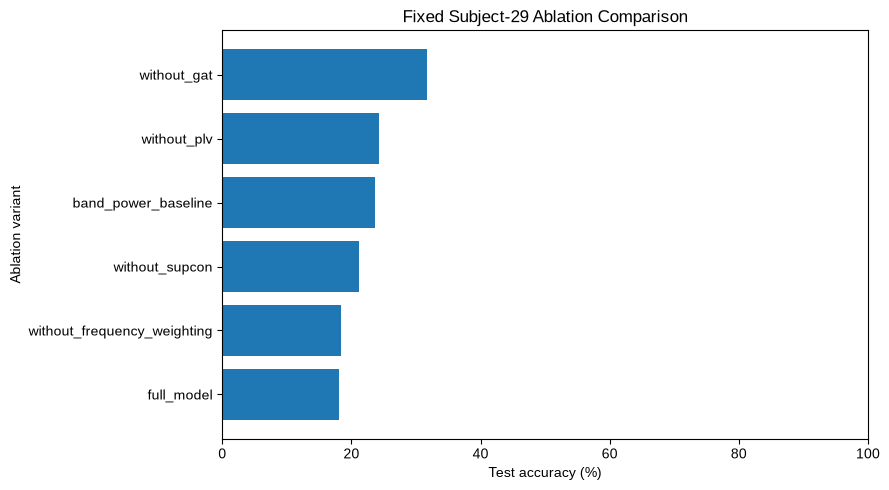

In [70]:
plot_df = ablation.sort_values(
    "test_accuracy",
    ascending=True,
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_df["variant"],
    plot_df["test_accuracy_%"],
)

plt.xlabel("Test accuracy (%)")
plt.ylabel("Ablation variant")
plt.title(
    "Fixed Subject-29 Ablation Comparison"
)

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 5. Supplementary metrics

Procrustes similarity, silhouette, kNN accuracy, Spearman correlation, and band weights are not primary evidence for the workload trajectory.

They may be reported in supplementary tables, but they should not replace the trajectory-position criterion.

The final primary claim should be based on:

1. subject-wise LOSO evaluation;
2. frozen Stage-2 calibration;
3. the predefined between-segment criterion;
4. exact confidence intervals;
5. PLV-threshold sensitivity;
6. ablation comparison.
